# Plate coefficient stability across cell subsets

**Question:** Are the plate effects estimated from QC reference cells (HeLa lysates,
site-specific QC) consistent with those estimated from single cells?
If so, QC-derived coefficients can be used to correct single cell data without the
cell-type / plate confound that arises when rare cells are concentrated on specific plates.

| Section | Content |
|---|---|
| 1 | Load data — all cell types including QCs |
| 2 | Estimate plate coefficients per subset |
| 3 | Coefficient stability comparison |
| 4 | QC-based batch correction of single cells |

---
## 0 — Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path(".").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib
matplotlib.rcParams["figure.dpi"] = 120

from batch_mixing.config import COL_PLATE, COL_CELLTYPE, RIDGE_ALPHA
from batch_mixing.correction import (
    impute_rowmean,
    remove_plate_effect,
    estimate_plate_coef,
    apply_plate_coefficients,
    plate_variance_ratio,
)
from batch_mixing.embedding import run_pca
from batch_mixing.metrics import compute_clustering
from batch_mixing.visualization import _plate_colours, _CELLTYPE_COLOURS

ANNDATA_IN = Path("/home/sam/SCI/SCI/Data/AnnData/out")
LAYER      = "X_log2"
print("Imports OK")

/home/sam/miniconda3/envs/sci_environment/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK


---
## 1 — Data loading

We load the **unfiltered** AnnData so that all cell types — single cells and QC
references alike — are available. The `source name` column identifies each cell's
origin. The outlier filter (`completeness_outlier`) is applied only to single cells,
not to QC samples, because it was calibrated for single-cell completeness distributions.

In [2]:
import anndata

adata_raw = anndata.read_h5ad(ANNDATA_IN / "adata_protein.h5ad")
adata_raw.X = adata_raw.layers[LAYER].copy()

print(f"Full dataset: {adata_raw.n_obs} cells x {adata_raw.n_vars} proteins")
print()
print("Source name counts:")
print(adata_raw.obs["source name"].value_counts().to_string())
print()
print("Plates:", sorted(adata_raw.obs[COL_PLATE].unique().tolist()))

Full dataset: 3114 cells x 7231 proteins

Source name counts:
source name
K562                    972
HEK293T                 972
Site specific QC        216
Sorting control         214
Processing control      213
QC - Hela               198
Site specific blanks    174
Cellenone blank         155

Plates: ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']


In [3]:
ALL_PLATES = sorted(adata_raw.obs[COL_PLATE].unique().tolist())

# Outlier-filtered single cells
sc_mask = (
    adata_raw.obs["source name"].isin(["HEK293T", "K562"]) &
    ~adata_raw.obs["completeness_outlier"].astype(bool)
)

SUBSETS = {
    "All SC":          adata_raw.obs["source name"].isin(["HEK293T", "K562"]) & ~adata_raw.obs["completeness_outlier"].astype(bool),
    "HEK293T":         (adata_raw.obs["source name"] == "HEK293T") & ~adata_raw.obs["completeness_outlier"].astype(bool),
    "K562":            (adata_raw.obs["source name"] == "K562")    & ~adata_raw.obs["completeness_outlier"].astype(bool),
    "QC - Hela":       adata_raw.obs["source name"] == "QC - Hela",
    "Site specific QC":adata_raw.obs["source name"] == "Site specific QC",
}

print(f"{'Subset':<22}  {'n_cells':>8}  {'plates':>6}  {'proteins (≥1 obs)':>18}")
print("-" * 62)
for name, mask in SUBSETS.items():
    sub    = adata_raw[mask]
    X      = np.array(sub.X, dtype=float)
    plates = sorted(sub.obs[COL_PLATE].unique())
    n_obs  = int((~np.isnan(X)).any(axis=0).sum())
    print(f"{name:<22}  {mask.sum():>8}  {len(plates):>6}  {n_obs:>18}")

Subset                   n_cells  plates   proteins (≥1 obs)
--------------------------------------------------------------
All SC                      1864       9                6836
HEK293T                      931       9                6607
K562                         933       9                6673
QC - Hela                    198       9                6329
Site specific QC             216       9                6387


---
## 2 — Plate coefficient estimation

For each subset, we fit a Ridge regression model:

$$\text{protein}_j \sim \text{plate\_dummy} + \varepsilon$$

using only observed (non-NaN) cells for each protein. The result is a
**(n_proteins × n_plates)** coefficient matrix for each subset.

NaN entries indicate proteins where the subset had fewer than 2 observed cells
or fewer than 2 plates represented — the plate effect cannot be estimated for those.

**Interpretation:** If QC-derived coefficients are stable and agree with those from
single cells, QC cells provide a reliable plate effect estimate that avoids the
cell-type / plate confound in the single-cell correction.

In [4]:
coef_dict = {}

for name, mask in SUBSETS.items():
    sub = adata_raw[mask]
    X   = np.array(sub.X, dtype=float)
    pl  = sub.obs[COL_PLATE].values

    coefs = estimate_plate_coef(X, pl, ALL_PLATES, alpha=RIDGE_ALPHA)

    n_valid = int(~np.all(np.isnan(coefs), axis=1).sum())
    n_valid = int(np.sum(~np.all(np.isnan(coefs), axis=1)))
    print(f"{name:<22}  proteins with valid coefs: {n_valid} / {coefs.shape[0]}")
    coef_dict[name] = coefs

print()
print(f"Coefficient matrix shape per subset: {coefs.shape}  (n_proteins x n_plates)")

All SC                  proteins with valid coefs: 5011 / 7231
HEK293T                 proteins with valid coefs: 4820 / 7231
K562                    proteins with valid coefs: 4878 / 7231
QC - Hela               proteins with valid coefs: 4828 / 7231
Site specific QC        proteins with valid coefs: 4851 / 7231

Coefficient matrix shape per subset: (7231, 9)  (n_proteins x n_plates)


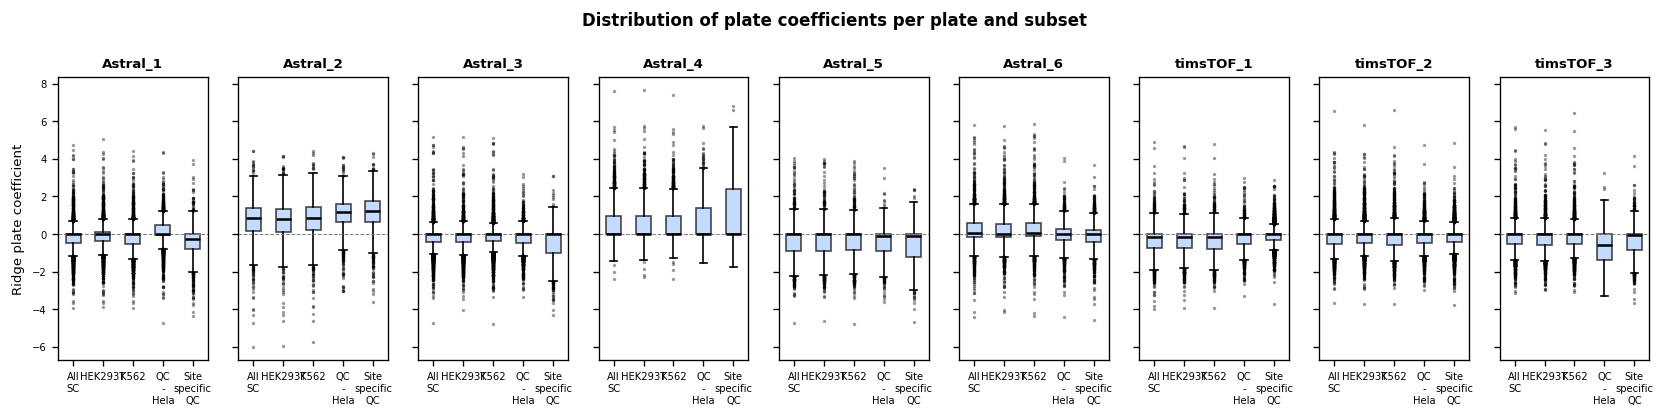

In [5]:
# Coefficient magnitude overview: mean |coef| per plate per subset
fig, axes = plt.subplots(1, len(ALL_PLATES), figsize=(14, 3.5), sharey=True)

for col, plate in enumerate(ALL_PLATES):
    ax = axes[col]
    vals   = []
    labels = []
    for name, coefs in coef_dict.items():
        c = coefs[:, col]
        c = c[~np.isnan(c)]
        vals.append(c)
        labels.append(name)

    ax.boxplot(vals, patch_artist=True,
               medianprops=dict(color="black", linewidth=1.5),
               flierprops=dict(marker=".", markersize=2, alpha=0.4),
               boxprops=dict(facecolor="#aaccff", alpha=0.7))
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels([l.replace(" ", "\n") for l in labels], fontsize=6)
    ax.set_title(plate, fontsize=8, fontweight="bold")
    ax.tick_params(labelsize=6)
    ax.axhline(0, color="grey", linewidth=0.6, linestyle="--")
    if col == 0:
        ax.set_ylabel("Ridge plate coefficient", fontsize=8)

fig.suptitle("Distribution of plate coefficients per plate and subset",
             fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 3 — Coefficient stability comparison

We compare plate coefficients estimated from different subsets using three views:

**3a — Global correlation heatmap:** Pearson *r* between the coefficient vectors
(all proteins × all plates concatenated) of each pair of subsets.
A value close to 1 means the two subsets produce nearly identical plate effect estimates.

**3b — Per-plate scatter plots:** For each plate, scatter of coefficients from
`All SC` (x-axis) against each QC reference (y-axis). Points cluster along the
diagonal if the estimates agree. Deviation indicates proteins whose plate effect
is estimated differently by the two sources.

**3c — Per-plate Pearson r:** Bar chart summarising agreement per plate between
`All SC` and each QC reference. Reveals whether certain plates are harder to
calibrate from QC cells.

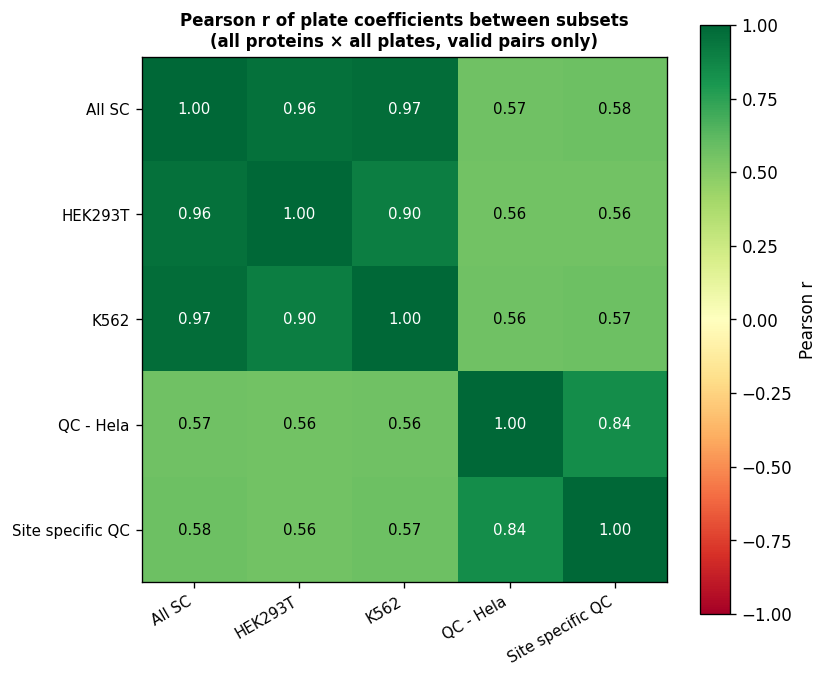

In [6]:
subset_names = list(coef_dict.keys())
n = len(subset_names)
corr_mat = np.full((n, n), np.nan)

for i, a in enumerate(subset_names):
    for j, b in enumerate(subset_names):
        ca   = coef_dict[a].ravel()
        cb   = coef_dict[b].ravel()
        valid = ~np.isnan(ca) & ~np.isnan(cb)
        if valid.sum() > 20:
            corr_mat[i, j] = np.corrcoef(ca[valid], cb[valid])[0, 1]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_mat, cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(n))
ax.set_xticklabels(subset_names, rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(n))
ax.set_yticklabels(subset_names, fontsize=9)
ax.set_title("Pearson r of plate coefficients between subsets\n"
             "(all proteins × all plates, valid pairs only)",
             fontsize=10, fontweight="bold")
for i in range(n):
    for j in range(n):
        if not np.isnan(corr_mat[i, j]):
            ax.text(j, i, f"{corr_mat[i, j]:.2f}", ha="center", va="center",
                    fontsize=9,
                    color="white" if abs(corr_mat[i, j]) > 0.7 else "black")
plt.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

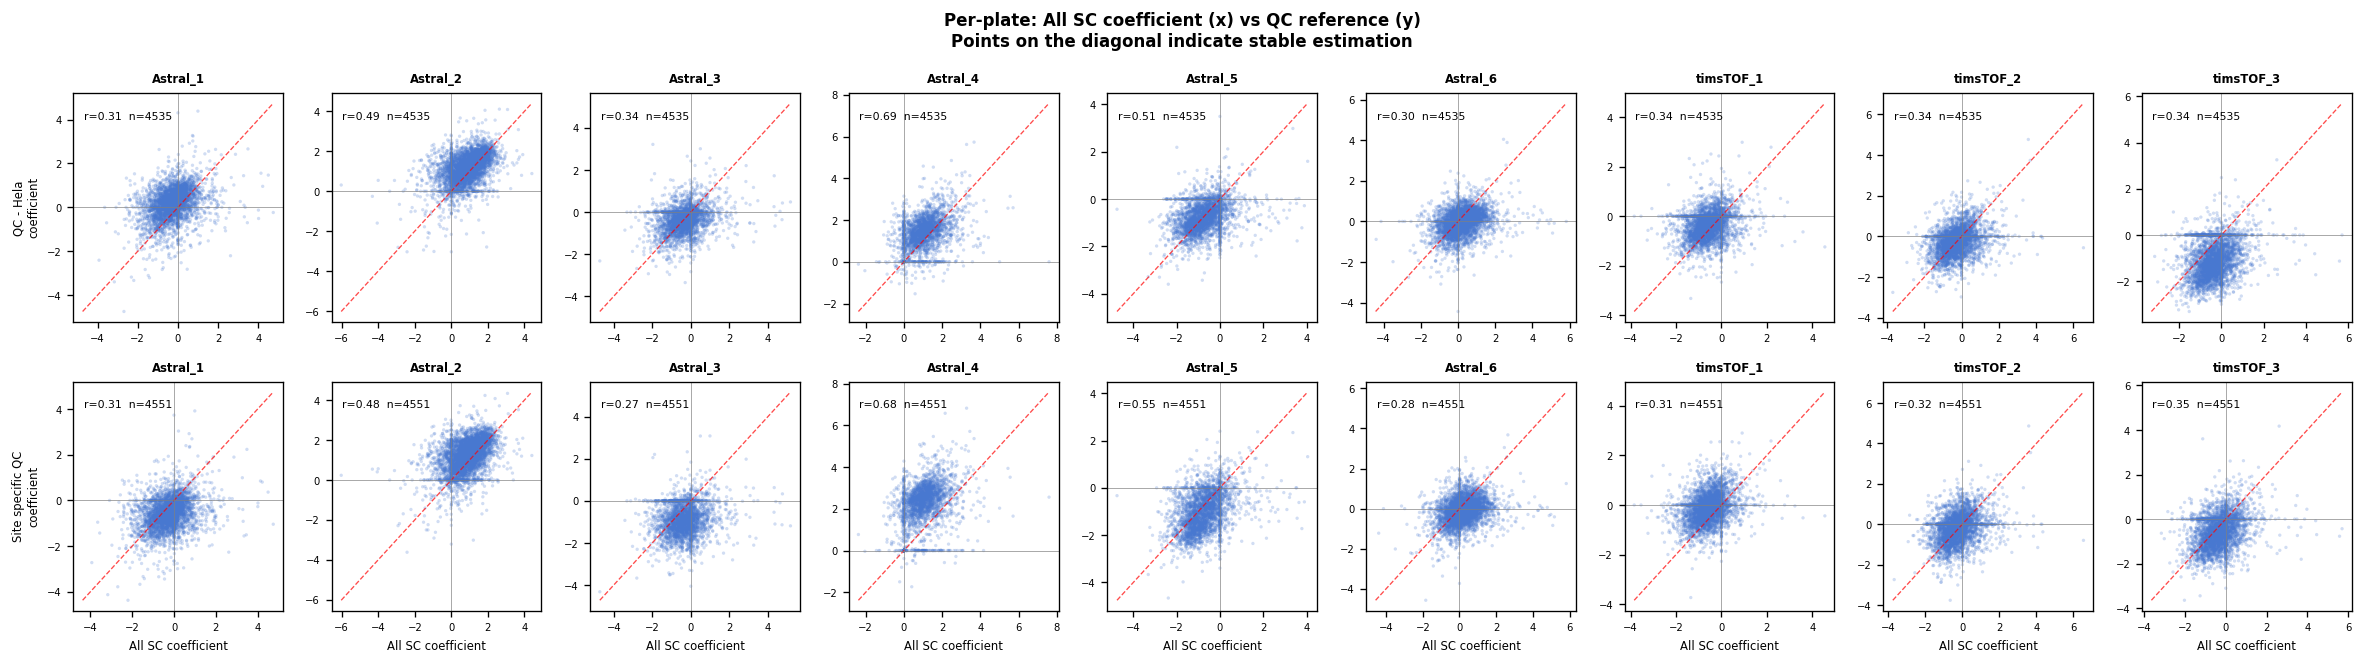

In [7]:
# Scatter: All SC coefs (x) vs QC reference coefs (y) per plate.
qc_refs = ["QC - Hela", "Site specific QC"]
n_cols  = len(ALL_PLATES)
n_rows  = len(qc_refs)

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(2.2 * n_cols, 2.8 * n_rows),
                         squeeze=False)

for row, ref in enumerate(qc_refs):
    ca_all = coef_dict["All SC"]
    cb_ref = coef_dict[ref]

    for col, plate in enumerate(ALL_PLATES):
        ax    = axes[row, col]
        ca    = ca_all[:, col]
        cb    = cb_ref[:, col]
        valid = ~np.isnan(ca) & ~np.isnan(cb)

        if valid.sum() > 5:
            ax.scatter(ca[valid], cb[valid],
                       alpha=0.25, s=4, color="#4878D0", edgecolors="none")
            r = np.corrcoef(ca[valid], cb[valid])[0, 1]
            lo = min(ca[valid].min(), cb[valid].min())
            hi = max(ca[valid].max(), cb[valid].max())
            ax.plot([lo, hi], [lo, hi], "r--", linewidth=0.8, alpha=0.7)
            ax.text(0.05, 0.92, f"r={r:.2f}  n={valid.sum()}",
                    transform=ax.transAxes, fontsize=6.5, va="top")
        else:
            ax.text(0.5, 0.5, f"n={valid.sum()}\n(too few)",
                    transform=ax.transAxes, ha="center", va="center",
                    fontsize=7, color="grey")
            ax.set_facecolor("#f8f8f8")

        ax.set_title(plate, fontsize=7, fontweight="bold")
        ax.tick_params(labelsize=6)
        ax.axhline(0, color="grey", linewidth=0.4)
        ax.axvline(0, color="grey", linewidth=0.4)

        if col == 0:
            ax.set_ylabel(f"{ref}\ncoefficient", fontsize=7)
        if row == n_rows - 1:
            ax.set_xlabel("All SC coefficient", fontsize=7)

fig.suptitle("Per-plate: All SC coefficient (x) vs QC reference (y)\n"
             "Points on the diagonal indicate stable estimation",
             fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

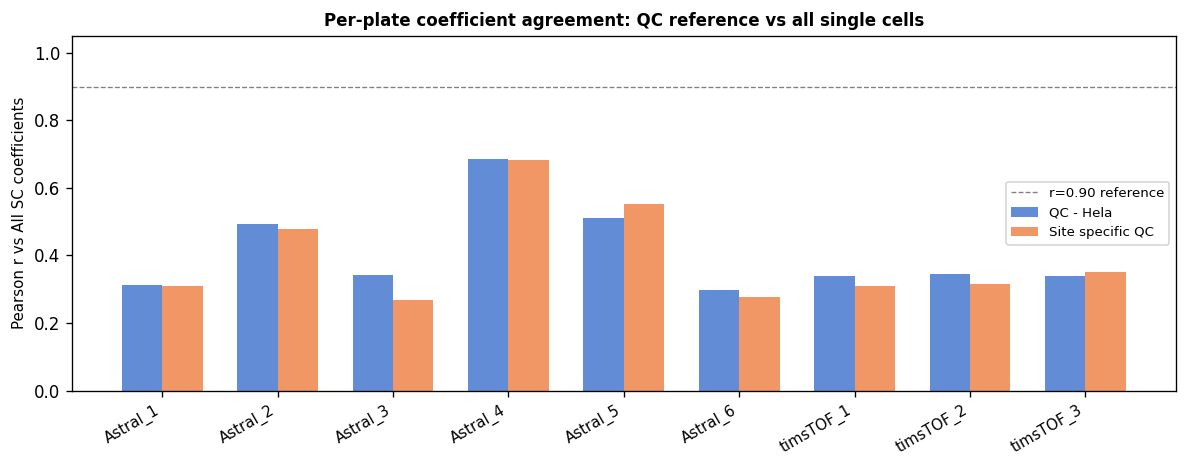

In [8]:
# Per-plate Pearson r bar chart: All SC vs each QC reference
fig, ax = plt.subplots(figsize=(10, 4))

x       = np.arange(len(ALL_PLATES))
width   = 0.35
colours = {"QC - Hela": "#4878D0", "Site specific QC": "#EE854A"}

for i, ref in enumerate(qc_refs):
    ca_all = coef_dict["All SC"]
    cb_ref = coef_dict[ref]
    rs = []
    for p_idx in range(len(ALL_PLATES)):
        ca    = ca_all[:, p_idx]
        cb    = cb_ref[:, p_idx]
        valid = ~np.isnan(ca) & ~np.isnan(cb)
        rs.append(np.corrcoef(ca[valid], cb[valid])[0, 1] if valid.sum() > 5 else np.nan)
    offset = (i - 0.5) * width
    bars = ax.bar(x + offset, rs, width, label=ref,
                  color=colours[ref], alpha=0.85, edgecolor="none")

ax.set_xticks(x)
ax.set_xticklabels(ALL_PLATES, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Pearson r vs All SC coefficients", fontsize=9)
ax.set_title("Per-plate coefficient agreement: QC reference vs all single cells",
             fontsize=10, fontweight="bold")
ax.axhline(0.9, color="grey", linestyle="--", linewidth=0.8, label="r=0.90 reference")
ax.legend(fontsize=8)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

---
## 4 — QC-based batch correction of single cells

We now apply the QC-derived plate coefficients to single cells and compare
the resulting PCA embeddings against two baselines:

| Method | How plate coefficients are estimated |
|---|---|
| **Raw** | No correction |
| **SC-corrected** | Coefficients estimated from the single cells themselves (current approach) |
| **Hela-corrected** | Coefficients estimated from `QC - Hela` cells, applied to SC |
| **Site-QC-corrected** | Coefficients estimated from `Site specific QC` cells, applied to SC |

**What to look for:**
- **Top row (cell type colouring):** HEK293T and K562 should remain separated after correction.
- **Bottom row (plate colouring):** Plate clusters should dissolve after correction — cells from different plates should mix.

The QC-based correction succeeds if it achieves comparable or better batch mixing
than the SC-based correction while preserving cell type separation. It is *especially*
useful when the single-cell dataset has a confounded plate/cell-type design.

In [9]:
# Use outlier-filtered single cells for the PCA comparison.
adata_sc = adata_raw[sc_mask].copy()

# Protein filter: keep proteins present in ≥50% of single cells
X_full   = np.array(adata_sc.X, dtype=float)
keep_mask = np.mean(~np.isnan(X_full), axis=0) >= 0.50
adata_sc  = adata_sc[:, keep_mask].copy()

X_raw        = np.array(adata_sc.X, dtype=float)
plate_labels = adata_sc.obs[COL_PLATE].values
ct_labels    = adata_sc.obs["source name"].values
protein_idx  = np.where(keep_mask)[0]   # maps filtered proteins back to full adata

print(f"Single cells : {adata_sc.n_obs} cells x {adata_sc.n_vars} proteins")
print(f"Plates       : {sorted(np.unique(plate_labels))}")
print(f"Cell types   : {dict(zip(*np.unique(ct_labels, return_counts=True)))}")

Single cells : 1864 cells x 1723 proteins
Plates       : ['Astral_1', 'Astral_2', 'Astral_3', 'Astral_4', 'Astral_5', 'Astral_6', 'timsTOF_1', 'timsTOF_2', 'timsTOF_3']
Cell types   : {'HEK293T': np.int64(931), 'K562': np.int64(933)}


In [18]:
coef_dict['All SC']

array([[-1.7727571 ,  0.71599931,  0.        , ...,  0.        ,
        -1.15118256,  0.        ],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [-1.22931345,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [-1.5914556 , -0.24660274, -0.82013706, ...,  0.55845655,
         1.38062481,  0.28554127],
       [-0.20498428,  0.62738676,  0.82594051, ..., -0.75781969,
        -0.1707092 , -0.16223161]], shape=(7231, 9))

In [20]:
coef_dict['QC - Hela']

array([[        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [-0.19175613,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [ 0.83653635,  1.49503292, -0.60859414, ..., -0.46436567,
        -0.16401497, -2.32674686],
       [ 0.24987888,  0.27123673, -0.37476812, ...,  0.33834505,
         0.04777781, -0.83680551]], shape=(7231, 9))

In [19]:
coef_dict['HEK293T']

array([[-2.14098493,  0.52691605,  0.        , ...,  0.        ,
        -1.16016773,  0.        ],
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [-1.22899347,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [-1.49041513, -0.0329525 , -0.87636899, ...,  0.46473666,
         1.3056489 ,  0.26374012],
       [-0.30813022,  0.64057639,  0.        , ..., -0.74463006,
        -0.05447979, -0.27041238]], shape=(7231, 9))

In [10]:
# 1. Imputed raw (baseline)
X_raw_imp = impute_rowmean(X_raw)

# 2. SC-based correction (standard)
X_corr_sc, _ = remove_plate_effect(X_raw, plate_labels)

# 3. QC - Hela correction
coef_hela = coef_dict["QC - Hela"][protein_idx]     # align to filtered proteins
X_corr_hela = apply_plate_coefficients(X_raw, plate_labels, coef_hela, ALL_PLATES)

# 4. Site specific QC correction
coef_site = coef_dict["Site specific QC"][protein_idx]
X_corr_site = apply_plate_coefficients(X_raw, plate_labels, coef_site, ALL_PLATES)

# PCA for all four
pcs_raw,  ve_raw  = run_pca(X_raw_imp)
pcs_sc,   ve_sc   = run_pca(X_corr_sc)
pcs_hela, ve_hela = run_pca(X_corr_hela)
pcs_site, ve_site = run_pca(X_corr_site)

print("PCA computed for all four correction strategies.")

# ARI for each
for label, pcs, ct in [
    ("Raw",          pcs_raw,  ct_labels),
    ("SC-corrected", pcs_sc,   ct_labels),
    ("Hela-corrected", pcs_hela, ct_labels),
    ("Site-corrected", pcs_site, ct_labels),
]:
    ari = compute_clustering(pcs, ct)["ari"]
    print(f"  {label:<22}  ARI = {ari:.3f}")

PCA computed for all four correction strategies.
  Raw                     ARI = -0.000
  SC-corrected            ARI = 0.979
  Hela-corrected          ARI = -0.000
  Site-corrected          ARI = -0.000


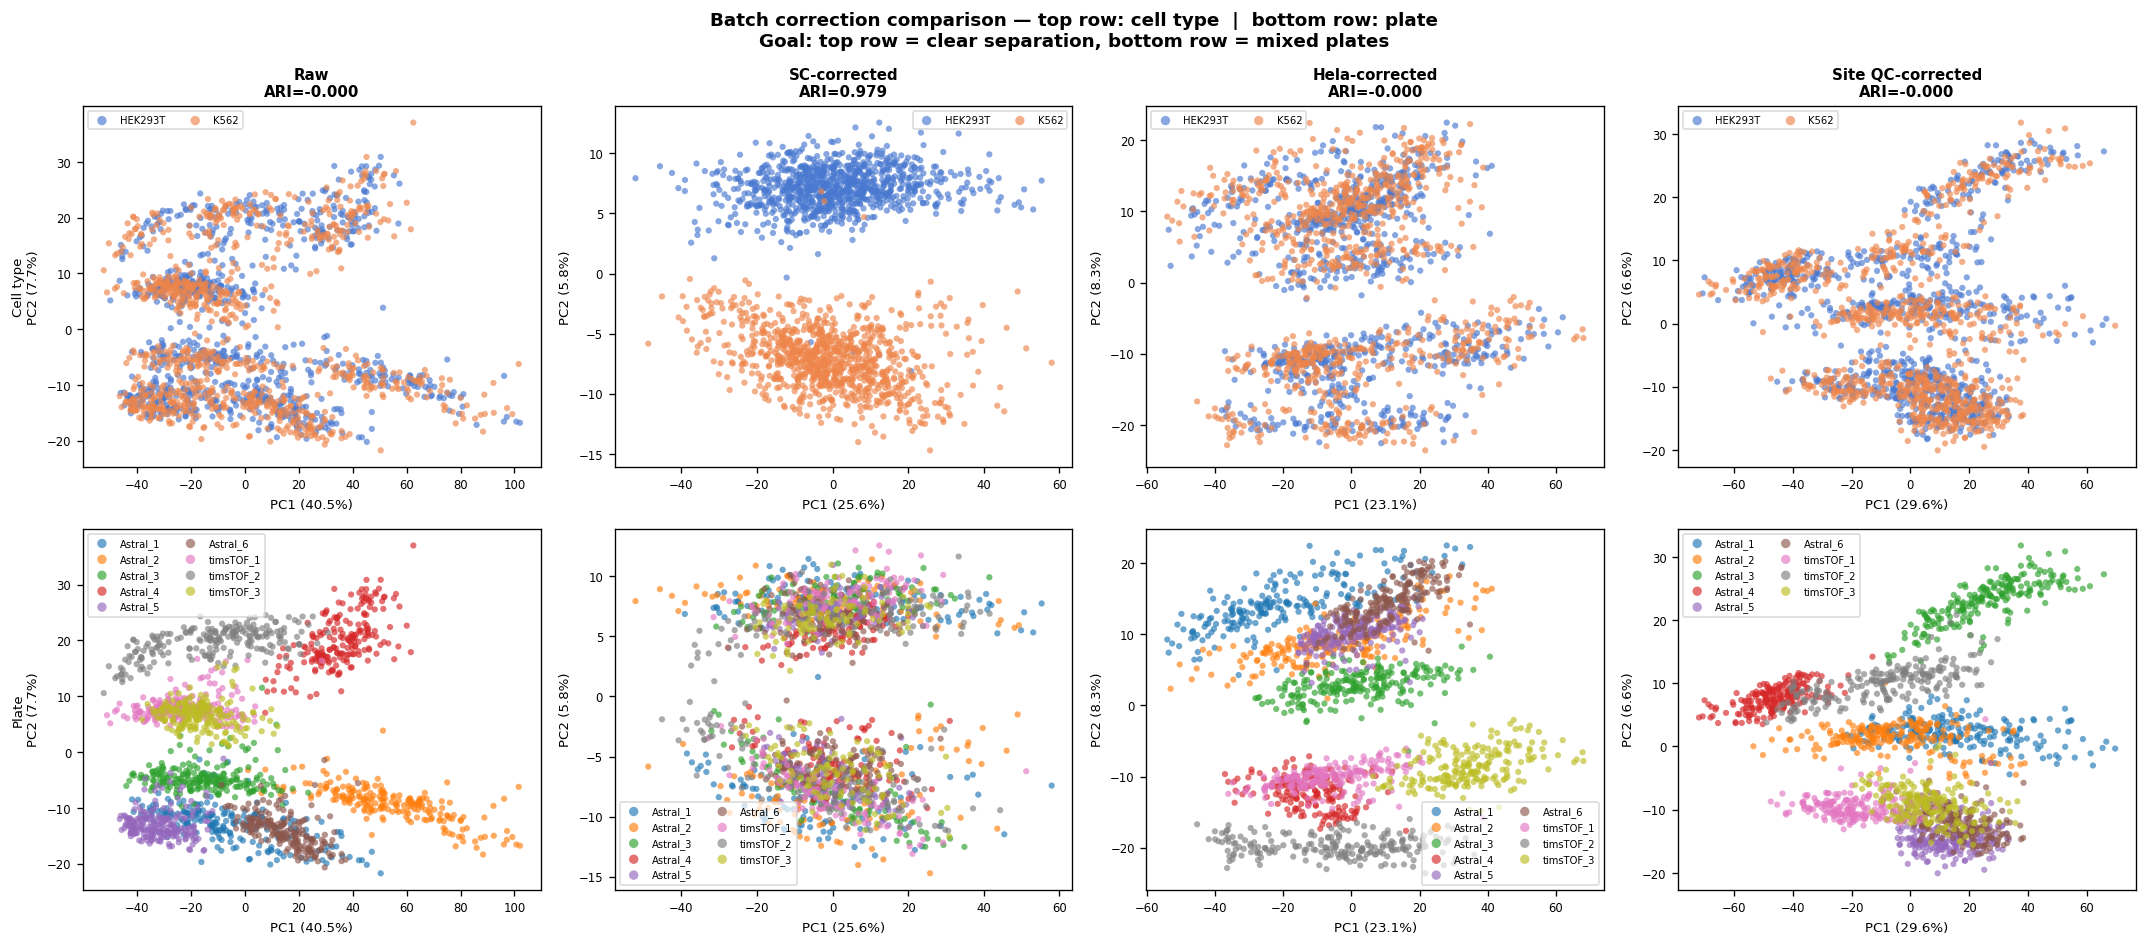

In [11]:
methods = [
    ("Raw",            pcs_raw,  ve_raw),
    ("SC-corrected",   pcs_sc,   ve_sc),
    ("Hela-corrected", pcs_hela, ve_hela),
    ("Site QC-corrected", pcs_site, ve_site),
]

ct_pal    = _CELLTYPE_COLOURS
plate_pal = _plate_colours(sorted(np.unique(plate_labels)))

fig, axes = plt.subplots(2, len(methods),
                         figsize=(4.5 * len(methods), 8),
                         squeeze=False)

for col, (method, pcs, ve) in enumerate(methods):
    for row, (labels, pal, row_title) in enumerate([
        (ct_labels,    ct_pal,    "Cell type"),
        (plate_labels, plate_pal, "Plate"),
    ]):
        ax = axes[row, col]
        for lbl in sorted(np.unique(labels)):
            mask = labels == lbl
            ax.scatter(pcs[mask, 0], pcs[mask, 1],
                       color=pal.get(str(lbl), pal.get(lbl, "grey")),
                       label=str(lbl), alpha=0.65, s=14, edgecolors="none")
        ax.set_xlabel(f"PC1 ({ve[0]:.1%})", fontsize=8)
        ax.set_ylabel(f"PC2 ({ve[1]:.1%})", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.legend(fontsize=6, markerscale=1.5, framealpha=0.7,
                  loc="best", ncol=2)
        if row == 0:
            ari = compute_clustering(pcs, ct_labels)["ari"]
            ax.set_title(f"{method}\nARI={ari:.3f}", fontsize=9, fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{row_title}\nPC2 ({ve[1]:.1%})", fontsize=8)

fig.suptitle(
    "Batch correction comparison — top row: cell type  |  bottom row: plate\n"
    "Goal: top row = clear separation, bottom row = mixed plates",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.show()

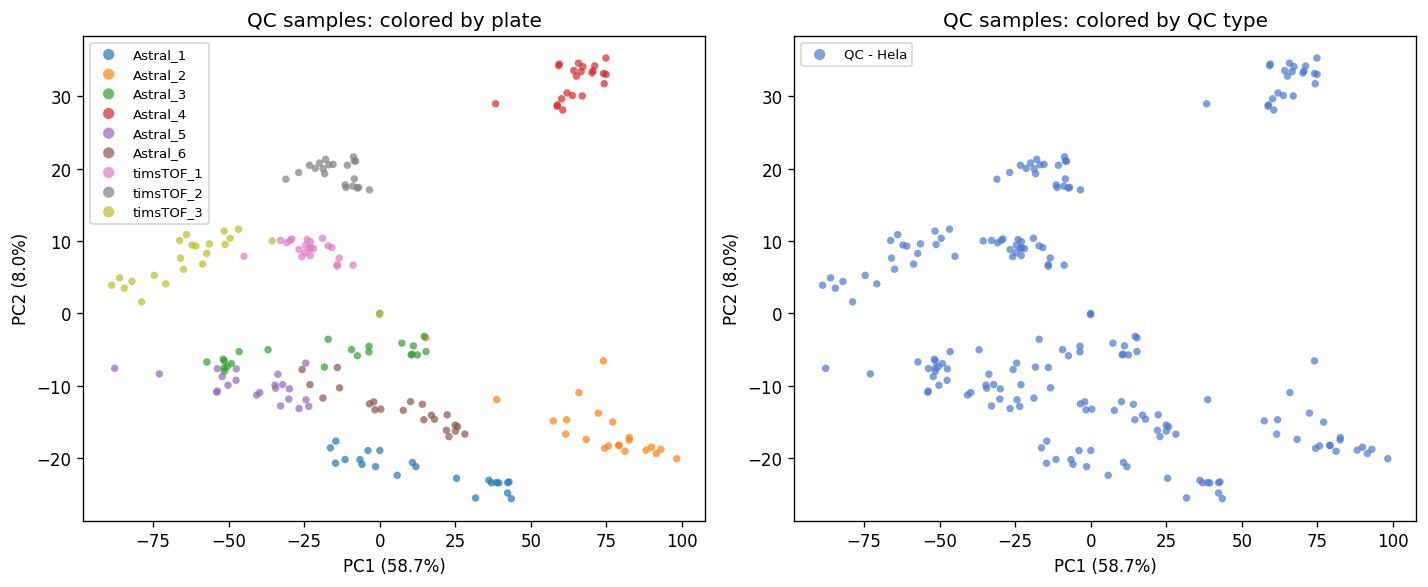

In [15]:
# Visualize QC samples in PCA space
qc_mask = adata_raw.obs["source name"].isin(["QC - Hela"])
adata_qc = adata_raw[qc_mask].copy()

# Protein filter: keep proteins present in ≥50% of QC samples (or skip if not needed)
X_qc_full = np.array(adata_qc.X, dtype=float)
keep_mask_qc = np.mean(~np.isnan(X_qc_full), axis=0) >= 0.50
adata_qc = adata_qc[:, keep_mask_qc].copy()

X_qc = np.array(adata_qc.X, dtype=float)
plate_labels_qc = adata_qc.obs[COL_PLATE].values
qc_labels = adata_qc.obs["source name"].values

# Impute missing values
X_qc_imp = impute_rowmean(X_qc)

# PCA
pcs_qc, ve_qc = run_pca(X_qc_imp)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Color by plate
ax = axes[0]
for lbl in sorted(np.unique(plate_labels_qc)):
    mask = plate_labels_qc == lbl
    ax.scatter(pcs_qc[mask, 0], pcs_qc[mask, 1],
               color=plate_pal.get(str(lbl), plate_pal.get(lbl, "grey")),
               label=str(lbl), alpha=0.7, s=20, edgecolors="none")
ax.set_xlabel(f"PC1 ({ve_qc[0]:.1%})")
ax.set_ylabel(f"PC2 ({ve_qc[1]:.1%})")
ax.set_title("QC samples: colored by plate")
ax.legend(fontsize=8, markerscale=1.5)

# Color by QC type
ax = axes[1]
qc_pal = {"QC - Hela": "#4878D0", "Site specific QC": "#EE854A"}
for lbl in sorted(np.unique(qc_labels)):
    mask = qc_labels == lbl
    ax.scatter(pcs_qc[mask, 0], pcs_qc[mask, 1],
               color=qc_pal.get(lbl, "grey"),
               label=lbl, alpha=0.7, s=20, edgecolors="none")
ax.set_xlabel(f"PC1 ({ve_qc[0]:.1%})")
ax.set_ylabel(f"PC2 ({ve_qc[1]:.1%})")
ax.set_title("QC samples: colored by QC type")
ax.legend(fontsize=8, markerscale=1.5)

plt.tight_layout()
plt.show()

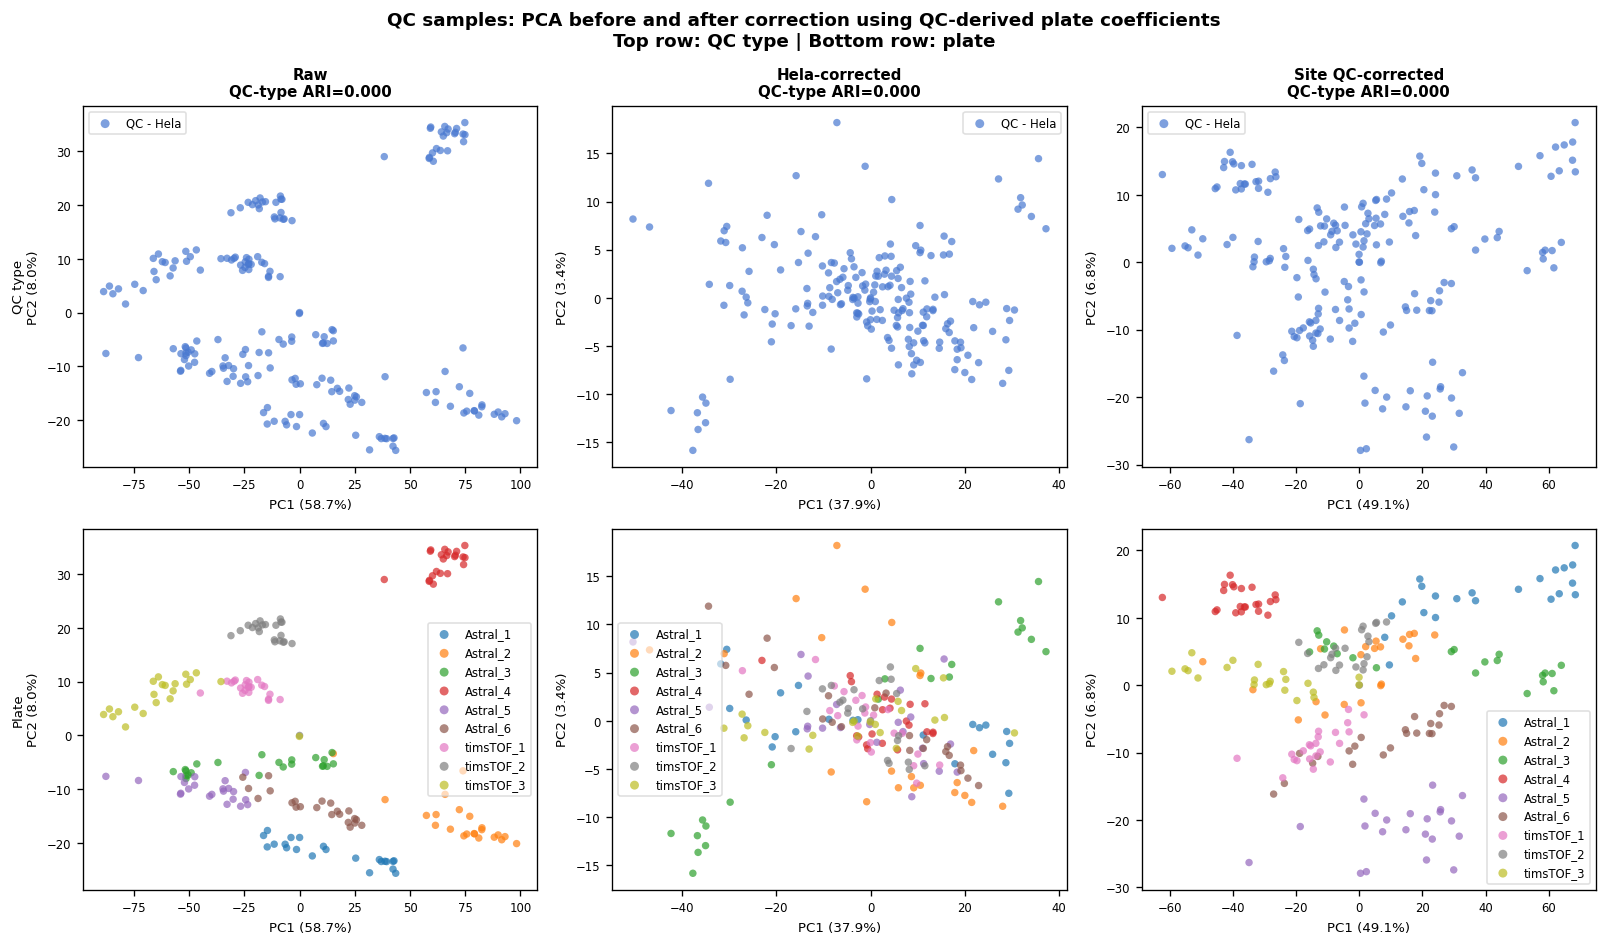

In [16]:
# Correct QC samples using QC-derived plate coefficients and compare PCA embeddings.
coef_hela_qc = coef_dict["QC - Hela"][keep_mask_qc]
coef_site_qc = coef_dict["Site specific QC"][keep_mask_qc]

X_qc_corr_hela = apply_plate_coefficients(X_qc, plate_labels_qc, coef_hela_qc, ALL_PLATES)
X_qc_corr_site = apply_plate_coefficients(X_qc, plate_labels_qc, coef_site_qc, ALL_PLATES)

pcs_qc_hela, ve_qc_hela = run_pca(X_qc_corr_hela)
pcs_qc_site, ve_qc_site = run_pca(X_qc_corr_site)

methods_qc = [
    ("Raw", pcs_qc, ve_qc),
    ("Hela-corrected", pcs_qc_hela, ve_qc_hela),
    ("Site QC-corrected", pcs_qc_site, ve_qc_site),
]

fig, axes = plt.subplots(2, len(methods_qc),
                         figsize=(4.5 * len(methods_qc), 8),
                         squeeze=False)

for col, (method, pcs, ve) in enumerate(methods_qc):
    for row, (labels, pal, row_title) in enumerate([
        (qc_labels, qc_pal, "QC type"),
        (plate_labels_qc, plate_pal, "Plate"),
    ]):
        ax = axes[row, col]
        for lbl in sorted(np.unique(labels)):
            mask = labels == lbl
            ax.scatter(pcs[mask, 0], pcs[mask, 1],
                       color=pal.get(lbl, "grey"),
                       label=str(lbl),
                       alpha=0.7, s=20, edgecolors="none")
        ax.set_xlabel(f"PC1 ({ve[0]:.1%})", fontsize=8)
        ax.set_ylabel(f"PC2 ({ve[1]:.1%})", fontsize=8)
        ax.tick_params(labelsize=7)

        if row == 0:
            ari = compute_clustering(pcs, qc_labels)["ari"]
            ax.set_title(f"{method}\nQC-type ARI={ari:.3f}", fontsize=9, fontweight="bold")
        if col == 0:
            ax.set_ylabel(f"{row_title}\nPC2 ({ve[1]:.1%})", fontsize=8)

        ax.legend(fontsize=7, markerscale=1.2, framealpha=0.6, loc="best", ncol=1)

fig.suptitle(
    "QC samples: PCA before and after correction using QC-derived plate coefficients\n"
    "Top row: QC type | Bottom row: plate",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.show()

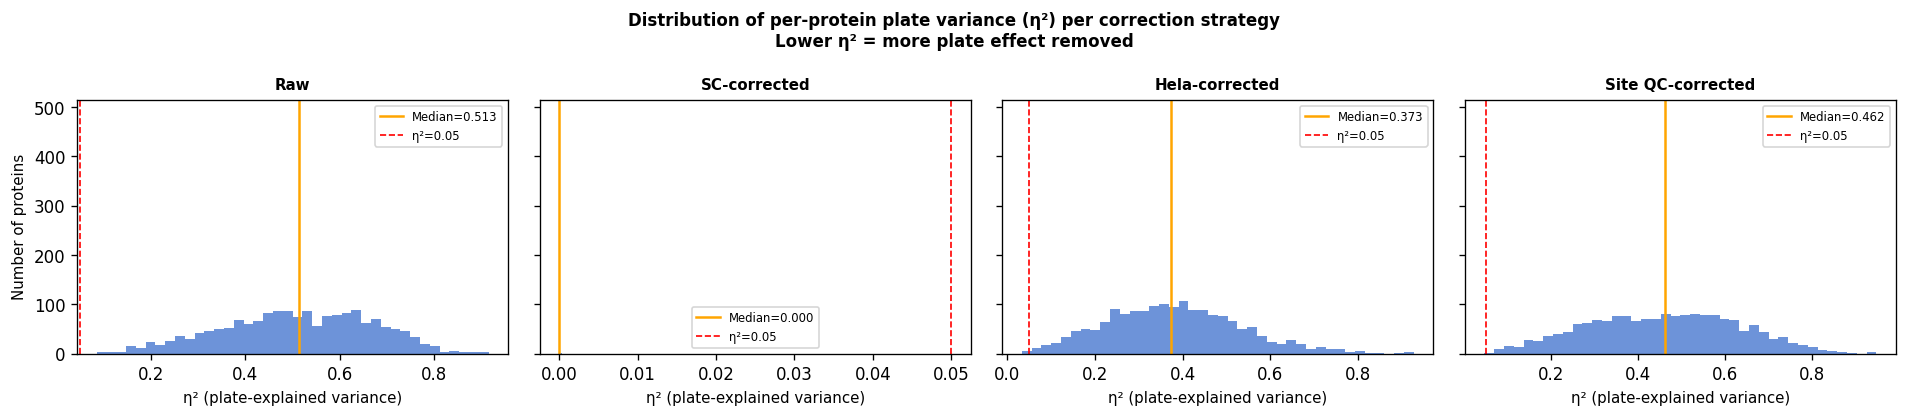

In [12]:
# Plate variance explained (η²) before and after each correction strategy.
from batch_mixing.correction import plate_variance_ratio

eta2_strategies = {
    "Raw":             X_raw_imp,
    "SC-corrected":    X_corr_sc,
    "Hela-corrected":  X_corr_hela,
    "Site QC-corrected": X_corr_site,
}

fig, axes = plt.subplots(1, len(eta2_strategies),
                         figsize=(4 * len(eta2_strategies), 3.5),
                         sharey=True)

for ax, (label, X) in zip(axes, eta2_strategies.items()):
    eta2 = plate_variance_ratio(X, plate_labels)
    ax.hist(eta2, bins=40, color="#4878D0", alpha=0.8, edgecolor="none")
    ax.axvline(np.nanmedian(eta2), color="orange", linewidth=1.5,
               label=f"Median={np.nanmedian(eta2):.3f}")
    ax.axvline(0.05, color="red", linewidth=1, linestyle="--",
               label="η²=0.05")
    ax.set_xlabel("η² (plate-explained variance)", fontsize=9)
    ax.set_title(label, fontsize=9, fontweight="bold")
    ax.legend(fontsize=7)
    if ax is axes[0]:
        ax.set_ylabel("Number of proteins", fontsize=9)

fig.suptitle("Distribution of per-protein plate variance (η²) per correction strategy\n"
             "Lower η² = more plate effect removed",
             fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Summary

The comparison above reveals whether QC cells provide a reliable proxy for
estimating the plate effect in single-cell proteomics:

- **High Pearson r** between QC-derived and SC-derived coefficients (Section 3)
  indicates that the technical plate effect is consistent across cell types and
  QC references — a prerequisite for QC-based correction to work.

- **Similar η² reduction** after QC-based correction (Section 4, bottom panel)
  indicates that the QC-derived coefficients remove as much plate-specific variance
  as the SC-derived coefficients.

- **Preserved or improved ARI** after QC-based correction indicates that
  cell-type biology is not degraded — and may be better preserved when the
  SC-based correction was confounded by an unbalanced cell-type / plate design.

**If the QC-based correction performs comparably:**  
Use `estimate_plate_coef` on QC cells, then `apply_plate_coefficients` on single cells.
This is the recommended strategy whenever the experiment includes reference QC channels
and the single-cell plate design is unbalanced with respect to cell type.